# Co-Determination of Kernel and Current Distribution in 1D
To zeroth order, the parameters of the SQUID are known in SOT. One aims for some particular height, knows the SQUID size from magnetotransport, and designs the setup to have some particular SQUID tilt angle. However, the true kernel is determined by small changes in AFM parameters, offsets and shifts in the mechanical parts, mechanical noise, and other factors.

To excellent approximation, these uncertainties can be captured by the parameters $h$ and $\phi$---the height and tilt angle of the SQUID. Especially in tapping-mode SQUID-on-tip, one true height does not exist due to the tapping motion, and height is therefore an "effective parameter". In the same vein, there are preliminary indictations that tapping mode AFM itself slightly varies the tilt angle. The precise kernel is highly sensitive to both parameters, so even these minute variations are important to compensate for.

For this reason, SOTtools supports co-determination of the kernel and current distribution in 1D. There are some caveats to this approach, and a naive co-determination will give either the wrong kernel of the wrong current distribution.

### Bi-level machinery
In the fixed-current problem, we rely on the minimization of a loss function $L(\mathbf{c}) = F(\mathbf{c}) + R(\mathbf{c})$ where $\mathbf{c}$ is some data vector representing the current, $F$ denotes fidelity and $R$ denotes regularization. Naively, adding in a hyperparameter vector $\mathbf{\theta}$ describing the SQUID, one would try to write a loss function $L(\mathbf{c}, \mathbf{\theta}) = F(\mathbf{c}, \mathbf{\theta}) + R(\mathbf{c})$ and minimize it with respect to both $\mathbf{c}$ and $\mathbf{\theta}$. However, this introduces an unwanted attractor: the model becomes biased towards kernels that improve regularization. This is completely unphysical: the choice of kernel must be based only on fidelity.

Therefore, we use an iterative bi-level approach. We iterate a set of two steps to convergence:

1. Fix the kernel and minimize the loss function with respect to the current distribution. This obtains some optimal current $\mathbf{c}^*(\mathbf{\theta})$.
2. Perform a single gradient descent step in the direction of $\frac{d}{d\mathbf{\theta}} F(\mathbf{c}^*(\mathbf{\theta}),\mathbf{\theta})=0$

This scheme alone generally fits a datset in a matter of seconds.

### Cross-validation and denoising
The bi-level approach as-stated still contains an unwanted attractor. If the same data is always fitted for both steps, the problem attempts to reduce the kernel size. A smaller kernel can after all fit the noise better, but this is unphysical.

For this reason, we perform cross-validation. In cross-validation, the dataset is split into two "folds". Each fold is itself a splitting of the dataset: half the dataset becomes the "test" set and the other half the "train" set. In SOTtools, these sets are always interleaved, as this is the natural way to filter out local outliers: only correlations consistent over the dataset are considered signal.

This changes the bi-level approach. In step 1, we still fix the parameter vector $\mathbf{\theta}$, but now we find two currents $\mathbf{c}^*_1$ and $\mathbf{c}^*_2$ that minimize the loss function on the two folds. In step 2, we then perform a single gradient descent step in the direction of $\frac{d}{d\mathbf{\theta}} F(\mathbf{c}^*_1(\mathbf{\theta}),\mathbf{\theta}) + \frac{d}{d\mathbf{\theta}} F(\mathbf{c}^*_2(\mathbf{\theta}),\mathbf{\theta})=0$. Crucially, this outer step is gauged against the *test* set---this is the key step that allows de-noising.

### Setting up the test problem
After this lengthy introduction, let's get to the code. As is now standard, we start from a Forward1D object and a true current distribution consisting of two gaussian peaks.


In [1]:
import sottools.forward as forward
import sottools.backward as backward
import numpy as np
import matplotlib.pyplot as plt

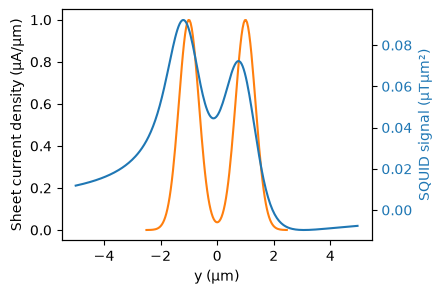

In [2]:
height_true = 0.5             # True height, that we will try to reconstruct later
phi_true = np.deg2rad(63.0)   # True tilt angle, that we will try to reconstruct later

params = forward.Forward1DParameters(
    Lscan = 10.0, # Scan length in microns
    Wdevice = 5.0, # Device (strip) width
    Nscan = 256, # Number of points in the SQUID scan
    gamma = 0.0,
    rho1 = 0.2,
    rho2 = 0.4,
    height = height_true,
    phi = phi_true, # Standard TM-SOT sensor tilt angle
    invert_normal=True # Sets the sign of the SQUID response
)
ydevice = params.ydevice.cpu().numpy() # Convert to NumPy from Torch
yscan = params.yscan.cpu().numpy() # Convert to NumPy from Torch
fwd = forward.Forward1D(params)

currents_two_gaussians = np.exp(-((ydevice+1.0)/0.5)**2) + np.exp(-((ydevice-1.0)/0.5)**2)
signal_two_gaussians = fwd.forward(currents_two_gaussians)

fig, ax = plt.subplots(1,1,figsize=(4,3))
ax.plot(ydevice, currents_two_gaussians, color='C1', label='Ground truth')
ax.set_xlabel('y (µm)')
ax.set_ylabel('Sheet current density (µA/µm)')

ax_signal = ax.twinx()
ax_signal.plot(yscan, signal_two_gaussians, color='C0', label='Signal')
ax_signal.set_ylabel('SQUID signal (µTµm²)', color='C0')
ax_signal.tick_params(axis='y', labelcolor='C0')

plt.show()

### Coinversion without noise and cross-validation
The simplest case is to do co-inversion without noise added onto the signal, and without any cross-validation.

Fit concluded for reason: converged


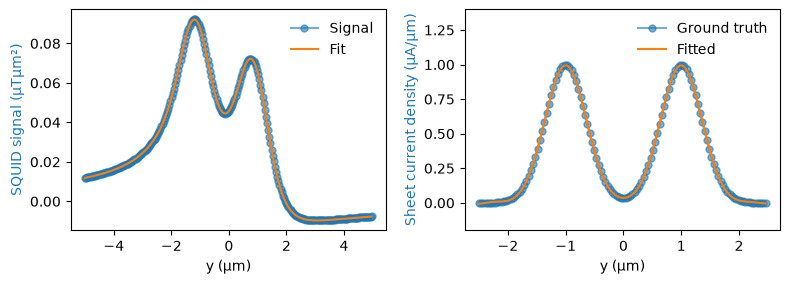

In [3]:
convergence_checker = backward.CoinversionConvergenceChecker(
    objtol = 1e-6,
    fidtol = 1e-6,
    heighttol = 1e-3,
    phitol = np.deg2rad(0.01),
    nwindow=10,
    nextrapolate=50,
)

coinverter = backward.Coinversion1D(
    fwd, # The forward.params object secretly contains the ground truth but Coinversion1D never looks at this object and therefore it does not matter for the validity of the test
    signal_two_gaussians,
    initial_height=1.0, # We start far off from the true height, to show that the algorithm can converge to the correct value
    initial_phi_eff=np.deg2rad(45.0),
    regularizer=1e-4*backward.Tikhonov1(),
    crossvalidation_size=1, # 1 fold, so no CV
    lr_sensor=1e-1,
    convergence_checker=convergence_checker,
)

res = coinverter.fit(
    n_steps_sensor=1000
)

print("Fit concluded for reason:", res["message"])

fig, (ax_fit, ax_current) = plt.subplots(1,2,figsize=(8,3))
ax_fit.plot(yscan, signal_two_gaussians, color='C0', label='Signal', marker='o', markersize=5, alpha=.6)
ax_fit.plot(yscan, coinverter.prediction, color='C1', label='Fit')
ax_fit.set_xlabel('y (µm)')
ax_fit.set_ylabel('SQUID signal (µTµm²)', color='C0')
ax_current.plot(ydevice, currents_two_gaussians, color='C0', label='Ground truth', marker='o', markersize=5, alpha=.6)
ax_current.plot(ydevice, coinverter.current, color='C1', label='Fitted')
ax_current.set_xlabel('y (µm)')
ax_current.set_ylabel('Sheet current density (µA/µm)', color='C0')
ax_current.set_ylim(-0.2, 1.4)
ax_fit.legend(frameon=False)
ax_current.legend(frameon=False)

plt.tight_layout()
plt.show()

We can plot the history of the fit to get an idea of how the sensor parameters converge to the true values alongside the loss function.

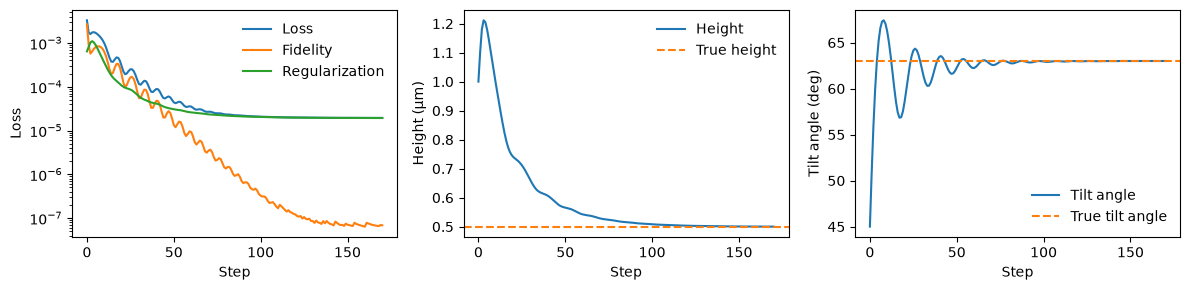

In [4]:
fig, axes = plt.subplots(1,3,figsize=(12,3))

hist = coinverter.history

# Axes 0: loss function, fidelity, and regularization
axes[0].plot(hist.objective_history, color='C0', label='Loss')
axes[0].plot(hist.fidelity_history, color='C1', label='Fidelity')
axes[0].plot(hist.regularization_history, color='C2', label='Regularization')
axes[0].set_xlabel('Step')
axes[0].set_ylabel('Loss')
axes[0].set_yscale('log')
axes[0].legend(frameon=False)

# Axes 1: height
axes[1].plot(hist.height_history, color='C0', label='Height')
axes[1].axhline(height_true, color='C1', linestyle='--', label='True height')
axes[1].set_xlabel('Step')
axes[1].set_ylabel('Height (µm)')

# Axes 2: tilt angle
axes[2].plot(np.rad2deg(hist.phi_history), color='C0', label='Tilt angle')
axes[2].axhline(np.rad2deg(phi_true), color='C1', linestyle='--', label='True tilt angle')
axes[2].set_xlabel('Step')
axes[2].set_ylabel('Tilt angle (deg)')
axes[1].legend(frameon=False)
axes[2].legend(frameon=False)
plt.tight_layout()
plt.show()

A critical eye spots some oscillations in the fidelity function, that could be smoothened out by annealing the learning rate. The class LearningRateScheduler can be used to implement this, but we will not do so here. The important point is that the algorithm converges to the correct values of height and tilt angle, and reconstructs the current distribution correctly.

### Adding noise in

Fit concluded for reason: converged


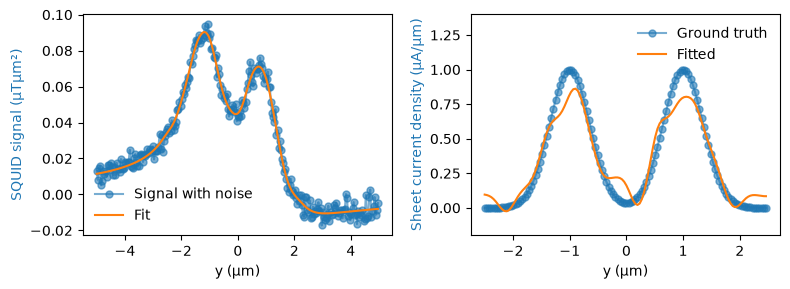

In [5]:
rng = np.random.default_rng(seed=42)  # For reproducibility

# SNR: 25
signal_with_noise = signal_two_gaussians + rng.normal(0, np.max(signal_two_gaussians)/25, size=signal_two_gaussians.shape)

# Repeat the fitting procedure with the noisy signal
coinverter_noise = backward.Coinversion1D(
    fwd,
    signal_with_noise,
    initial_height=1.0,
    initial_phi_eff=np.deg2rad(45.0),
    regularizer=7e-4*backward.Tikhonov1(),
    crossvalidation_size=1, # 2 folds for cross-validation
    lr_sensor=1e-1,
    convergence_checker=convergence_checker,
)

res_noise = coinverter_noise.fit(
    n_steps_sensor=1000
)

print("Fit concluded for reason:", res_noise["message"])

fig, (ax_fit_noise, ax_current_noise) = plt.subplots(1,2,figsize=(8,3))
ax_fit_noise.plot(yscan, signal_with_noise, color='C0', label='Signal with noise', marker='o', markersize=5, alpha=.6)
ax_fit_noise.plot(yscan, coinverter_noise.prediction, color='C1', label='Fit')
ax_fit_noise.set_xlabel('y (µm)')
ax_fit_noise.set_ylabel('SQUID signal (µTµm²)', color='C0')
ax_current_noise.plot(ydevice, currents_two_gaussians, color='C0', label='Ground truth', marker='o', markersize=5, alpha=.6)
ax_current_noise.plot(ydevice, coinverter_noise.current, color='C1', label='Fitted')
ax_current_noise.set_xlabel('y (µm)')
ax_current_noise.set_ylabel('Sheet current density (µA/µm)', color='C0')
ax_current_noise.set_ylim(-0.2, 1.4)
ax_fit_noise.legend(frameon=False)
ax_current_noise.legend(frameon=False)
plt.tight_layout()
plt.show()

Note how we increased the regularizer weight from $10^{-4}$ to $10^{-3}$. This still does not give a perfect reconstruction. We can again plot the history of the fit and see how well the sensor parameters were reconstructed in this case.

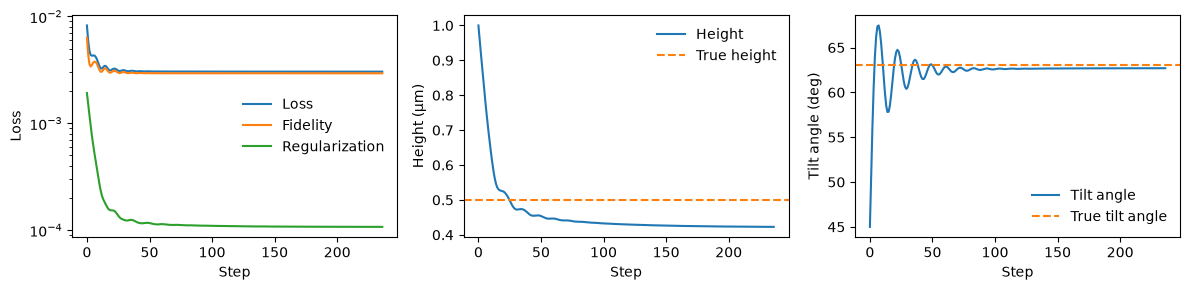

In [6]:
fig, axes = plt.subplots(1,3,figsize=(12,3))

hist = coinverter_noise.history

# Axes 0: loss function, fidelity, and regularization
axes[0].plot(hist.objective_history, color='C0', label='Loss')
axes[0].plot(hist.fidelity_history, color='C1', label='Fidelity')
axes[0].plot(hist.regularization_history, color='C2', label='Regularization')
axes[0].set_xlabel('Step')
axes[0].set_ylabel('Loss')
axes[0].set_yscale('log')
axes[0].legend(frameon=False)

# Axes 1: height
axes[1].plot(hist.height_history, color='C0', label='Height')
axes[1].axhline(height_true, color='C1', linestyle='--', label='True height')
axes[1].set_xlabel('Step')
axes[1].set_ylabel('Height (µm)')

# Axes 2: tilt angle
axes[2].plot(np.rad2deg(hist.phi_history), color='C0', label='Tilt angle')
axes[2].axhline(np.rad2deg(phi_true), color='C1', linestyle='--', label='True tilt angle')
axes[2].set_xlabel('Step')
axes[2].set_ylabel('Tilt angle (deg)')
axes[1].legend(frameon=False)
axes[2].legend(frameon=False)
plt.tight_layout()
plt.show()

While the sensor angle is reconstructed quite wel, the height is far too low: almost at the point where the SQUID would touch the sample surface. The reason is simple: there is a lot of noise, and a smaller kernel can fit the noise better. We must therefore introduce the cross-validation step.

### Co-determination with noise and cross-validation

Fit concluded for reason: converged


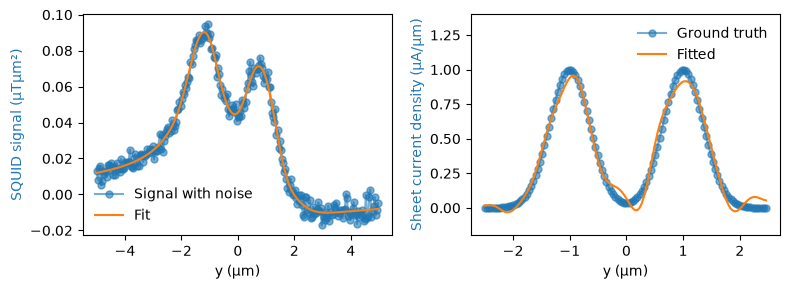

In [7]:
# Repeat the fitting procedure with the noisy signal
coinverter_noise_cv = backward.Coinversion1D(
    fwd,
    signal_with_noise,
    initial_height=1.0,
    initial_phi_eff=np.deg2rad(45.0),
    regularizer=7e-4*backward.Tikhonov1(),
    crossvalidation_size=2, # 2 folds for cross-validation
    lr_sensor=1e-1,
    convergence_checker=convergence_checker,
)

res_noise_cv = coinverter_noise_cv.fit(
    n_steps_sensor=1000
)

print("Fit concluded for reason:", res_noise["message"])

fig, (ax_fit_noise, ax_current_noise) = plt.subplots(1,2,figsize=(8,3))
ax_fit_noise.plot(yscan, signal_with_noise, color='C0', label='Signal with noise', marker='o', markersize=5, alpha=.6)
ax_fit_noise.plot(yscan, coinverter_noise_cv.prediction, color='C1', label='Fit')
ax_fit_noise.set_xlabel('y (µm)')
ax_fit_noise.set_ylabel('SQUID signal (µTµm²)', color='C0')
ax_current_noise.plot(ydevice, currents_two_gaussians, color='C0', label='Ground truth', marker='o', markersize=5, alpha=.6)
ax_current_noise.plot(ydevice, coinverter_noise_cv.current, color='C1', label='Fitted')
ax_current_noise.set_xlabel('y (µm)')
ax_current_noise.set_ylabel('Sheet current density (µA/µm)', color='C0')
ax_current_noise.set_ylim(-0.2, 1.4)
ax_fit_noise.legend(frameon=False)
ax_current_noise.legend(frameon=False)
plt.tight_layout()
plt.show()

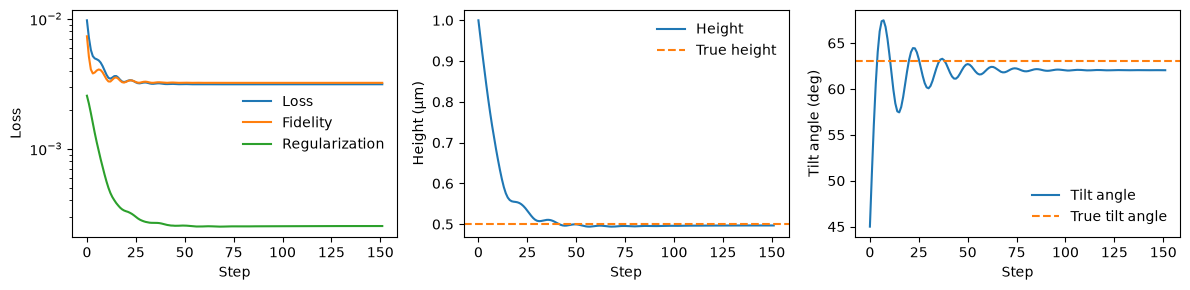

In [8]:
fig, axes = plt.subplots(1,3,figsize=(12,3))

hist = coinverter_noise_cv.history

# Axes 0: loss function, fidelity, and regularization
axes[0].plot(hist.objective_history, color='C0', label='Loss')
axes[0].plot(hist.fidelity_history, color='C1', label='Fidelity')
axes[0].plot(hist.regularization_history, color='C2', label='Regularization')
axes[0].set_xlabel('Step')
axes[0].set_ylabel('Loss')
axes[0].set_yscale('log')
axes[0].legend(frameon=False)

# Axes 1: height
axes[1].plot(hist.height_history, color='C0', label='Height')
axes[1].axhline(height_true, color='C1', linestyle='--', label='True height')
axes[1].set_xlabel('Step')
axes[1].set_ylabel('Height (µm)')

# Axes 2: tilt angle
axes[2].plot(np.rad2deg(hist.phi_history), color='C0', label='Tilt angle')
axes[2].axhline(np.rad2deg(phi_true), color='C1', linestyle='--', label='True tilt angle')
axes[2].set_xlabel('Step')
axes[2].set_ylabel('Tilt angle (deg)')
axes[1].legend(frameon=False)
axes[2].legend(frameon=False)
plt.tight_layout()
plt.show()

Although perfection cannot be achieved---noise inevitably murks the reconstruction---introducting CV has considerably improved the reconstruction of the sensor parameters, despite the relatively poor SNR of 25.